<div style="text-align: center;">

# The Causal Effect of Smoking Cessation on Weight Gain
### An Observational Study using the NHEFS Dataset

**Authors:** Adrian , Michael, Tina Sikharulidze

**Date:** March 2026

</div>

## Abstract

*[To be Done :) ]*

## 1. Introduction

<div style="text-align: justify;">

This project uses data from the National Health and Nutrition Examination Survey Epidemiologic Follow-up Study (NHEFS) to investigate the relationship between smoking cessation and weight gain. The data is collected in observational setting in which treatment assignment is not randomized. In this context, the central causal question is whether quitting smoking leads to a change in body weight, and if so, by how much.

</div>

### 1.1 Research Question

Our research question is **what is the average causal effect of smoking cessation on weight gain over a ten-year follow-up period?**

More precisely, we seek to estimate the weight change (in kg) from 1971 to 1982 that would be *caused* by quitting smoking, averaged over the NHEFS study population, as opposed to the weight change we would observe if no one had quit.

### 1.2 Variables

We define the following variables, all measured at or before the 1971 baseline interview.

| Symbol | NHEFS variable | Type | Description |
|--------|---------------|------|-------------|
| $D_i$ | `qsmk` | Binary | Treatment: 1 if individual $i$ quit smoking by the 1982 follow-up, 0 otherwise |
| $Y_i$ | `wt82_71` | Continuous | Outcome: weight change in kg from 1971 to 1982 |
| $W_i$ | mix of variables | Mixed | Baseline pre-treatment covariates measured in 1971 containing baseline confounders |

### 1.3 Potential Outcomes and the Estimand

We adopt the **potential outcomes** (Neyman) framework. For each individual $i$, we define:

- $Y_i(1)$: the weight change individual $i$ *would experience* if they quit smoking ($D_i = 1$)
- $Y_i(0)$: the weight change individual $i$ *would experience* if they continued smoking ($D_i = 0$)

These two quantities are in fact counterfactuals for any given individual, because only one is observed in the real world. As we learned, this is the **fundamental problem of causal inference**.

Our target estimand is the **Average Treatment Effect (ATE)**:

$$\text{ATE} = E\bigl[Y_i(1) - Y_i(0)\bigr]$$

This quantity represents the average difference in weight gain that would be caused by quitting smoking versus continuing to smoke, in the NHEFS study population. A positive ATE indicates that quitting causes weight gain on average, which as we researched is consistent with the pharmacological literature on nicotine suppression of appetite.

We target the ATE rather than the Average Treatment Effect on the Treated (ATT) because we are interested in the population-level question: what would happen if everyone quit, not only among those who actually did quit.

### 1.4 Identification Assumptions

The ATE is not directly observable because we never observe both $Y_i(1)$ and $Y_i(0)$ for the same individual. For this reason, we need to make three important assumptions that, taken together, allow us to express the ATE as a function of the observed data distribution $P(Y, D, W)$.

---

#### Assumption 1: SUTVA (Stable Unit Treatment Value Assumption)

**Statement.** For all individuals $i$ and treatment values $d \in \{0,1\}$:

$$Y_i = Y_i(D_i) \quad \text{and} \quad Y_i(d) \text{ is well-defined and unique}$$

This has two components:

1. **No interference**: individual $i$'s potential outcomes do not depend on the treatment received by any other individual $j \neq i$.
2. **Consistency / no multiple versions of treatment**: there is a single, well-defined version of "quitting smoking", so $D_i = 1$ maps to a unique potential outcome $Y_i(1)$.

**Justification.** The outcome of interest, weight change, is a private biological outcome primarily determined by individual physiology, diet, and behavior. While direct interference between units is implausible, we acknowledge that mild indirect interference cannot be entirely ruled out, for instance, if a household member quits smoking, shared dietary habits and home food environments may shift in ways that affect another household member's weight. However, given that NHEFS does not sample multiple individuals from the same household and that such spillover effects are likely small in magnitude relative to the direct biological effect of cessation, we treat the no-interference component of SUTVA as a reasonable working assumption. The consistency component is more subtle: `qsmk` is defined as complete abstinence from cigarettes by the 1982 follow-up, which is a reasonably homogeneous treatment. We acknowledge that the *route* to quitting (gradual reduction, nicotine replacement or other methods) may vary and could introduce slight heterogeneity in the treatment, but we treat this as negligible given the measurement of NHEFS.

---

#### Assumption 2: Conditional Ignorability

$$Y_i(0),\, Y_i(1) \;\perp\!\!\!\perp\; D_i \mid W_i$$

Conditional on the observed baseline covariates $W_i$, treatment assignment is independent of potential outcomes. In other words, within strata of $W$, individuals who quit smoking and those who did not are exchangeable.

**Justification.** Our justification relies on the causal DAG and the adjustment set identified through the PC algorithm in Section 2. The baseline confounders in $W$ block all non-causal paths between $D$ and $Y$: they capture the main biological determinants of both quitting behavior (smoking history, health-consciousness proxied by exercise) and weight change (baseline weight, age, metabolic factors). No variable in $W$ is a collider or a post-treatment variable, ensuring that conditioning on $W$ does not open spurious paths. The empirical check of this assumption, including which variables enter the adjustment set and how we verified the absence of colliders is presented in **Section 2 (PC Algorithm)**. Of course, we cannot rule out unmeasured confounding entirely; we discuss this limitation in the Discussion.

---

#### Assumption 3: Positivity (Overlap)

For all covariate values $w$ in the support of $W$:

$$0 < P(D_i = 1 \mid W_i = w) < 1$$

Every type of individual, as characterized by their baseline covariates, must have a positive probability of both quitting and not quitting smoking.

**Justification.** Positivity is required for the ATE to be well-defined across all covariate strata. If some subgroup has zero probability of quitting, the counterfactual $Y(1)$ is undefined for that group and the ATE cannot be identified without extrapolation. The empirical verification of this assumption is presented in **Section 3.1 (Positivity Check)**.

### 1.5 Identification Result

Under Assumptions 1–3, we can **nonparametrically** identify the ATE from the observed data:

$$E\bigl[Y_i(1) - Y_i(0)\bigr] = E_W\Bigl[E[Y_i \mid D_i = 1,\, W_i] - E[Y_i \mid D_i = 0,\, W_i]\Bigr]$$

The right-hand side is a function of the observed distribution $P(Y, D, W)$ only. This result justifies the two estimation strategies we use:

- **IP Weighting (IPW)**: reweighting the observations by $1/P(D \mid W)$ to create a population in which $D$ and $W$ are independent.
- **Double ML (PLR)**: partialling out $W$ from both $Y$ and $D$ via flexible ML models, then estimating the treatment effect by OLS of the residuals.

### 1.6 Method Justifications

**Justification for the PC Algorithm**

As we learned, the PC algorithm is a constraint-based causal discovery method that recovers the Markov equivalence class of the underlying DAG from conditional independence tests in the observed data. We use it for two purposes: to guide the selection of the adjustment set $W$, and to detect colliders in the variable set that would be invisible to purely theory-driven covariate selection.

Our key motivation is that conditioning on a collider opens a previously blocked non-causal path between $D$ and $Y$, introducing bias even when all confounders are correctly included. Since we are working with many variables that may interact in non-obvious ways, identifying colliders by domain knowledge alone is difficult. The PC algorithm detects v-structures $X \rightarrow C \leftarrow Z$ directly from the pattern of conditional independencies in the data, providing a data-based check on our theoretical assumptions.

---

**Justification for the Partially Linear Regression (PLR) Model**

We write the outcome equation as:

$$Y_i = \theta D_i + g(W_i) + \varepsilon_i, \qquad E[\varepsilon_i \mid D_i, W_i] = 0$$

where $\theta \in \mathbb{R}$ is the constant ATE parameter of interest and $g: \mathcal{W} \rightarrow \mathbb{R}$ is an unknown nuisance function capturing the effect of baseline covariates on weight gain. The key restriction of the PLR is that the relationship between treatment and outcome is **linear and additive**, the effect of quitting smoking on weight gain is assumed to be the same constant $\theta$ for every individual. The function $g(W)$ is estimated flexibly by XGBoost, removing the need for parametric assumptions on confounding. Identification of $\theta$ follows from the Neyman orthogonality condition: after partialling out $W$ from both $Y$ and $D$, the resulting residuals satisfy $E[\tilde{Y} \mid \tilde{D}] = \theta \tilde{D}$, so $\theta$ is recovered by OLS. We use $K=5$ fold cross-fitting to avoid overfitting bias.

---

**Justification for IPW**

IPW reweights each observation by the inverse of its propensity score $P(D=1 \mid W)$, creating a pseudo-population in which treatment is independent of covariates. We use stabilized weights $\frac{P(D)}{P(D \mid W)}$ which have lower variance than naive $1/P(D \mid W)$ weights. The propensity score is estimated using a calibrated XGBoost model, and we verify covariate balance after weighting as an empirical check of model adequacy.

### 1.7 Exploratory Data Analysis

Before undertaking formal causal estimation, we develop a clear understanding of the structure and quality of the data. The EDA is descriptive rather than causal. Its purpose is to examine the composition of the dataset, identify variables most relevant to the treatment and outcome of interest, assess missingness, and describe baseline differences between quitters and non-quitters.

#### Setup

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)

np.random.seed(42)

In [2]:
project_dir = Path.cwd()
data_dir = project_dir / "data"

df = pd.read_csv(data_dir / "nhefs_complete.csv")
codebook = pd.read_csv(data_dir / "nhefs_codebook.csv")

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (1566, 67)


,seqn,qsmk,death,yrdth,modth,dadth,sbp,dbp,sex,age,race,income,marital,school,education,ht,wt71,wt82,wt82_71,birthplace,smokeintensity,smkintensity82_71,smokeyrs,asthma,bronch,tb,hf,hbp,pepticulcer,colitis,hepatitis,chroniccough,hayfever,diabetes,polio,tumor,nervousbreak,alcoholpy,alcoholfreq,alcoholtype,alcoholhowmuch,pica,headache,otherpain,weakheart,allergies,nerves,lackpep,hbpmed,boweltrouble,wtloss,infection,active,exercise,birthcontrol,pregnancies,cholesterol,hightax82,price71,price82,tax71,tax82,price71_82,tax71_82,id,censored,older
0,233,0,0,NaN,NaN,NaN,175.0,96.0,0,42,1,19.0,2,7,1,174.1875,79.04,68.946040,-10.093960,47.0,30,-10,29,0,0,0,0,1,1,0,0,0,0,1,0,0,0,1,1,3,7.0,0,1,0,0,0,0,0,1,0,0,0,0,2,2,NaN,197.0,0.0,2.183594,1.739990,1.102295,0.461975,0.443787,0.640381,1,0,0
1,235,0,0,NaN,NaN,NaN,123.0,80.0,0,36,0,18.0,2,9,2,159.3750,58.63,61.234970,2.604970,42.0,20,-10,24,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,4.0,0,1,0,0,0,0,0,0,0,0,1,0,0,2,NaN,301.0,0.0,2.346680,1.797363,1.364990,0.571899,0.549316,0.792969,2,0,0
2,244,0,0,NaN,NaN,NaN,115.0,75.0,1,56,1,15.0,3,11,2,168.5000,56.81,66.224486,9.414486,51.0,20,-14,26,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,3,4,NaN,0,1,1,0,0,1,0,0,0,0,0,0,2,0,2.0,157.0,0.0,1.569580,1.513428,0.551270,0.230988,0.056198,0.320251,3,0,1
3,245,0,1,85.0,2.0,14.0,148.0,78.0,0,68,1,15.0,3,5,1,170.1875,59.42,64.410117,4.990117,37.0,3,4,53,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,2,3,4.0,0,0,1,1,0,0,0,0,0,0,0,1,2,2,NaN,174.0,0.0,1.506592,1.451904,0.524902,0.219971,0.054794,0.304993,4,0,1
4,252,0,0,NaN,NaN,NaN,118.0,77.0,0,40,0,18.0,2,11,2,181.8750,87.09,92.079251,4.989251,42.0,20,0,19,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,2,1,2.0,0,1,0,0,0,0,0,0,1,0,0,1,1,2,NaN,216.0,0.0,2.346680,1.797363,1.364990,0.571899,0.549316,0.792969,5,0,0


In [3]:
df_clean = df.copy()

#### 1.7.1 Dataset Overview

The dataset contains 1,566 observations and 67 variables. The main treatment variable is `qsmk`, which indicates whether an individual quit smoking between baseline and the 1982 follow-up. The primary outcome is `wt82_71`, the change in weight between 1971 and 1982. Baseline smoking behavior is captured by `smokeintensity` (cigarettes per day in 1971) and `smokeyrs` (years smoked at baseline).

In [4]:
# Check for variable name mismatches between codebook and dataset
codebook["variable"] = codebook["variable"].replace({
    "bithcontrol": "birthcontrol",
    "smkintensity 82_71": "smkintensity82_71"
})

code_vars = set(codebook["variable"].astype(str).str.strip())
data_vars = set(df.columns.astype(str).str.strip())

print("Variables in codebook but NOT in dataset:", sorted(code_vars - data_vars))
print("Variables in dataset but NOT in codebook:", sorted(data_vars - code_vars))

Variables in codebook but NOT in dataset: []
Variables in dataset but NOT in codebook: ['censored', 'id', 'older']


#### 1.7.2 Missingness

Some variables contain explicit NaN values. In addition, the codebook shows that certain variables use special codes such as `2` to indicate missing information, and categories labeled as Unknown. We handle both.

In [5]:
nan_summary = pd.DataFrame({
    "variable": df_clean.columns,
    "dtype": df_clean.dtypes.astype(str).values,
    "n_missing": df_clean.isna().sum().values,
    "pct_missing": (df_clean.isna().mean() * 100).round(2).values
})
nan_summary = nan_summary[nan_summary["n_missing"] > 0].sort_values(
    ["n_missing", "pct_missing"], ascending=[False, False]
).reset_index(drop=True)

print(f"Variables with explicit NaN: {nan_summary.shape[0]}")
nan_summary

Variables with explicit NaN: 17


,variable,dtype,n_missing,pct_missing
0,yrdth,float64,1275,81.42
1,modth,float64,1271,81.16
2,dadth,float64,1271,81.16
3,pregnancies,float64,866,55.30
4,alcoholhowmuch,float64,397,25.35
5,birthplace,float64,90,5.75
6,hightax82,float64,90,5.75
7,price71,float64,90,5.75
8,price82,float64,90,5.75
9,tax71,float64,90,5.75


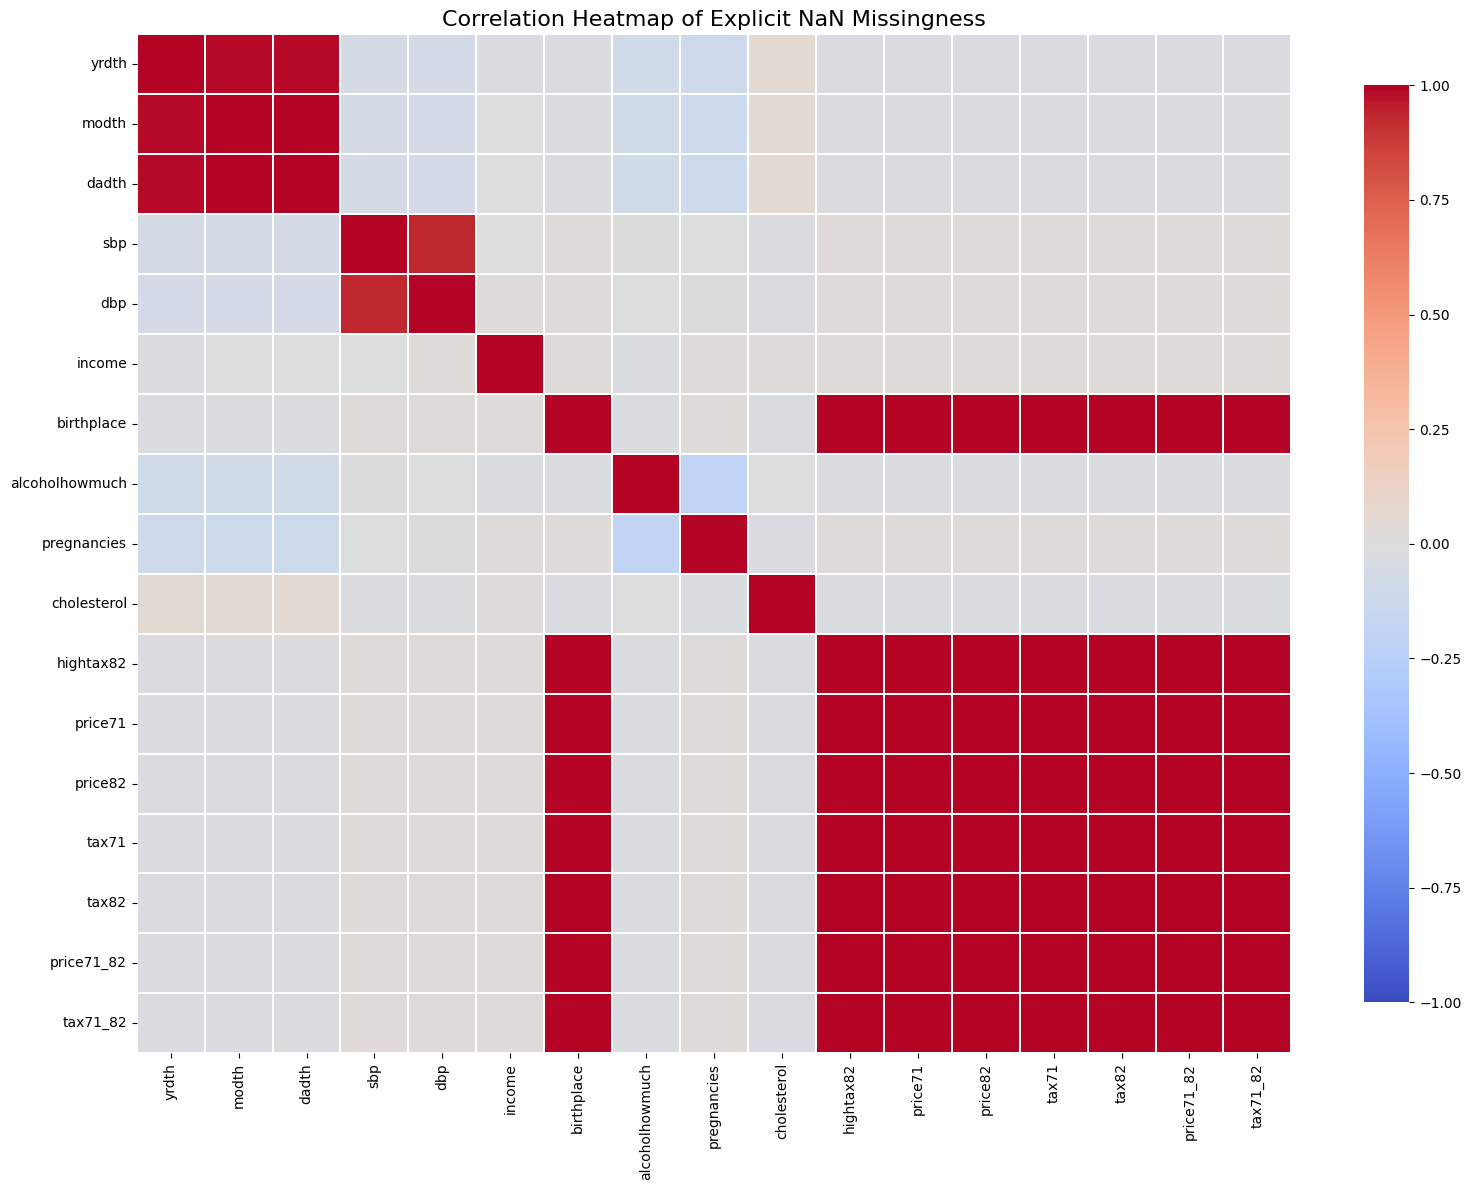

In [6]:
nan_vars = df_clean.columns[df_clean.isna().sum() > 0]
missing_matrix_nan = df_clean[nan_vars].isna().astype(int)
missing_corr_nan = missing_matrix_nan.corr()

plt.figure(figsize=(16, 12))
ax = sns.heatmap(missing_corr_nan, cmap="coolwarm", center=0, vmin=-1, vmax=1,
                 linewidths=0.2, linecolor="white", cbar_kws={"shrink": 0.9})
ax.set_title("Correlation Heatmap of Explicit NaN Missingness", fontsize=16)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

We also identify variables with coded missing values using the codebook — specifically variables where `2 = Missing`, plus `marital = 8 (Unknown)` and `alcoholfreq = 5 (Unknown)`.

In [7]:
mask_2_missing = codebook["description"].str.contains(
    r"2\s*:\s*MISSING", case=False, na=False, regex=True
)
vars_2_missing = codebook.loc[mask_2_missing, "variable"].tolist()
vars_2_missing = [col for col in vars_2_missing if col in df_clean.columns]

special_missing_codes = {col: 2 for col in vars_2_missing}
special_missing_codes["marital"] = 8
special_missing_codes["alcoholfreq"] = 5

special_missing_summary = pd.DataFrame({
    "variable": list(special_missing_codes.keys()),
    "missing_code": list(special_missing_codes.values()),
    "n_special_code": [(df_clean[var] == code).sum() for var, code in special_missing_codes.items()],
    "pct_special_code": [round((df_clean[var] == code).mean() * 100, 2) for var, code in special_missing_codes.items()],
}).sort_values("n_special_code", ascending=False).reset_index(drop=True)

special_missing_summary

,variable,missing_code,n_special_code,pct_special_code
0,birthcontrol,2,769,49.11
1,hbpmed,2,769,49.11
2,boweltrouble,2,769,49.11
3,diabetes,2,769,49.11
4,hbp,2,769,49.11
5,pica,2,769,49.11
6,alcoholpy,2,5,0.32
7,alcoholfreq,5,5,0.32
8,marital,8,1,0.06


In [8]:
for var, code in special_missing_codes.items():
    df_clean[f"{var}_missing"] = (df_clean[var].isna() | (df_clean[var] == code)).astype(int)
    df_clean[var] = df_clean[var].replace(code, np.nan)

after_recode_summary = pd.DataFrame({
    "variable": list(special_missing_codes.keys()),
    "n_missing_after": [df_clean[var].isna().sum() for var in special_missing_codes.keys()],
    "pct_missing_after": [round(df_clean[var].isna().mean() * 100, 2) for var in special_missing_codes.keys()],
}).sort_values("n_missing_after", ascending=False).reset_index(drop=True)

after_recode_summary

,variable,n_missing_after,pct_missing_after
0,birthcontrol,769,49.11
1,hbpmed,769,49.11
2,boweltrouble,769,49.11
3,diabetes,769,49.11
4,hbp,769,49.11
5,pica,769,49.11
6,alcoholpy,5,0.32
7,alcoholfreq,5,0.32
8,marital,1,0.06


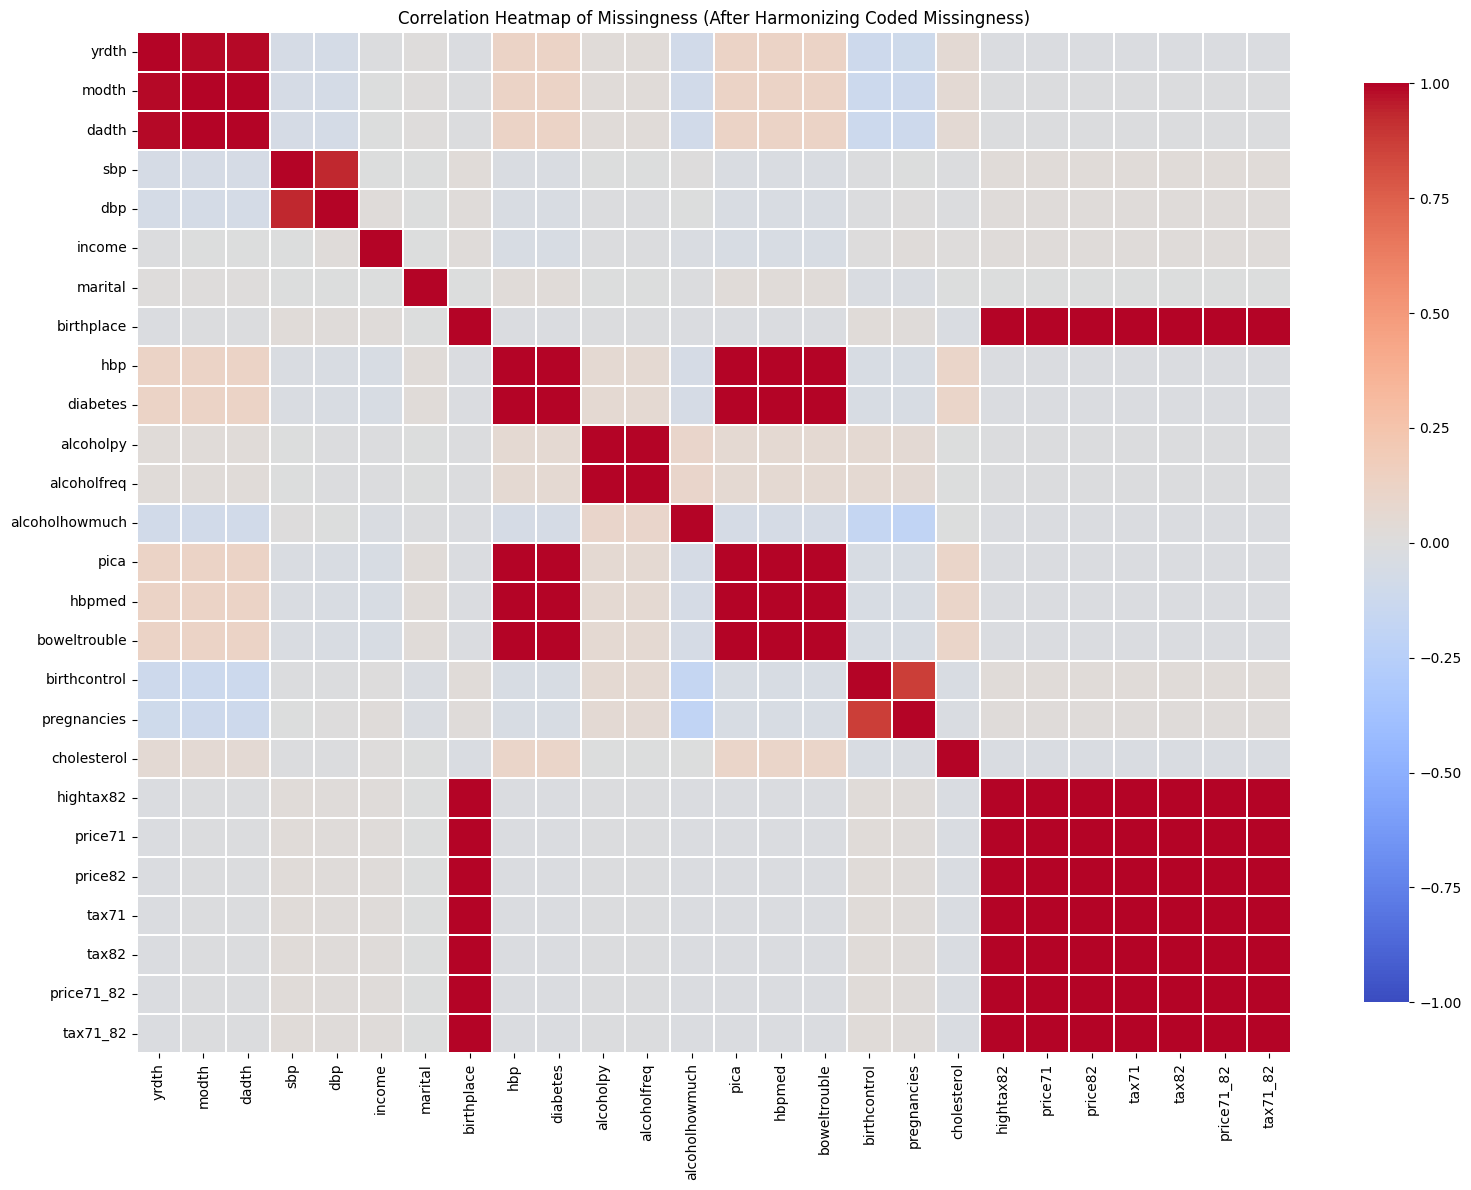

In [9]:
nan_vars_after = df_clean.columns[df_clean.isna().sum() > 0]
missing_matrix_after = df_clean[nan_vars_after].isna().astype(int)
missing_corr_after = missing_matrix_after.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(missing_corr_after, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.2, linecolor="white", cbar_kws={"shrink": 0.9})
plt.title("Correlation Heatmap of Missingness (After Harmonizing Coded Missingness)")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### 1.7.3 Sparse Binary Variables

We check which binary variables have fewer than 5% of observations with `value == 1`. These are rare conditions that will have too few positive cases to be useful as confounders. CI tests lack power in small cells, and including them risks adding spurious edges to the learned graph. We drop them from the analysis.

In [10]:
# Identify binary variables (only 0 and 1 as non-null values)
binary_cols = [col for col in df_clean.columns
               if df_clean[col].dropna().isin([0, 1]).all()
               and df_clean[col].nunique() == 2]

rare_binary = pd.DataFrame({
    "variable": binary_cols,
    "pct_value_1": [(df_clean[col] == 1).mean() * 100 for col in binary_cols]
}).sort_values("pct_value_1")

rare_binary_flagged = rare_binary[rare_binary["pct_value_1"] < 5].reset_index(drop=True)
print(f"Binary variables with < 5% positive cases: {len(rare_binary_flagged)}")
rare_binary_flagged

Binary variables with < 5% positive cases: 16


,variable,pct_value_1
0,marital_missing,0.063857
1,alcoholpy_missing,0.319285
2,alcoholfreq_missing,0.319285
3,pica,0.383142
4,hf,0.510856
5,diabetes,0.766284
6,tb,1.340996
7,polio,1.404853
8,hepatitis,1.787995
9,weakheart,2.234994


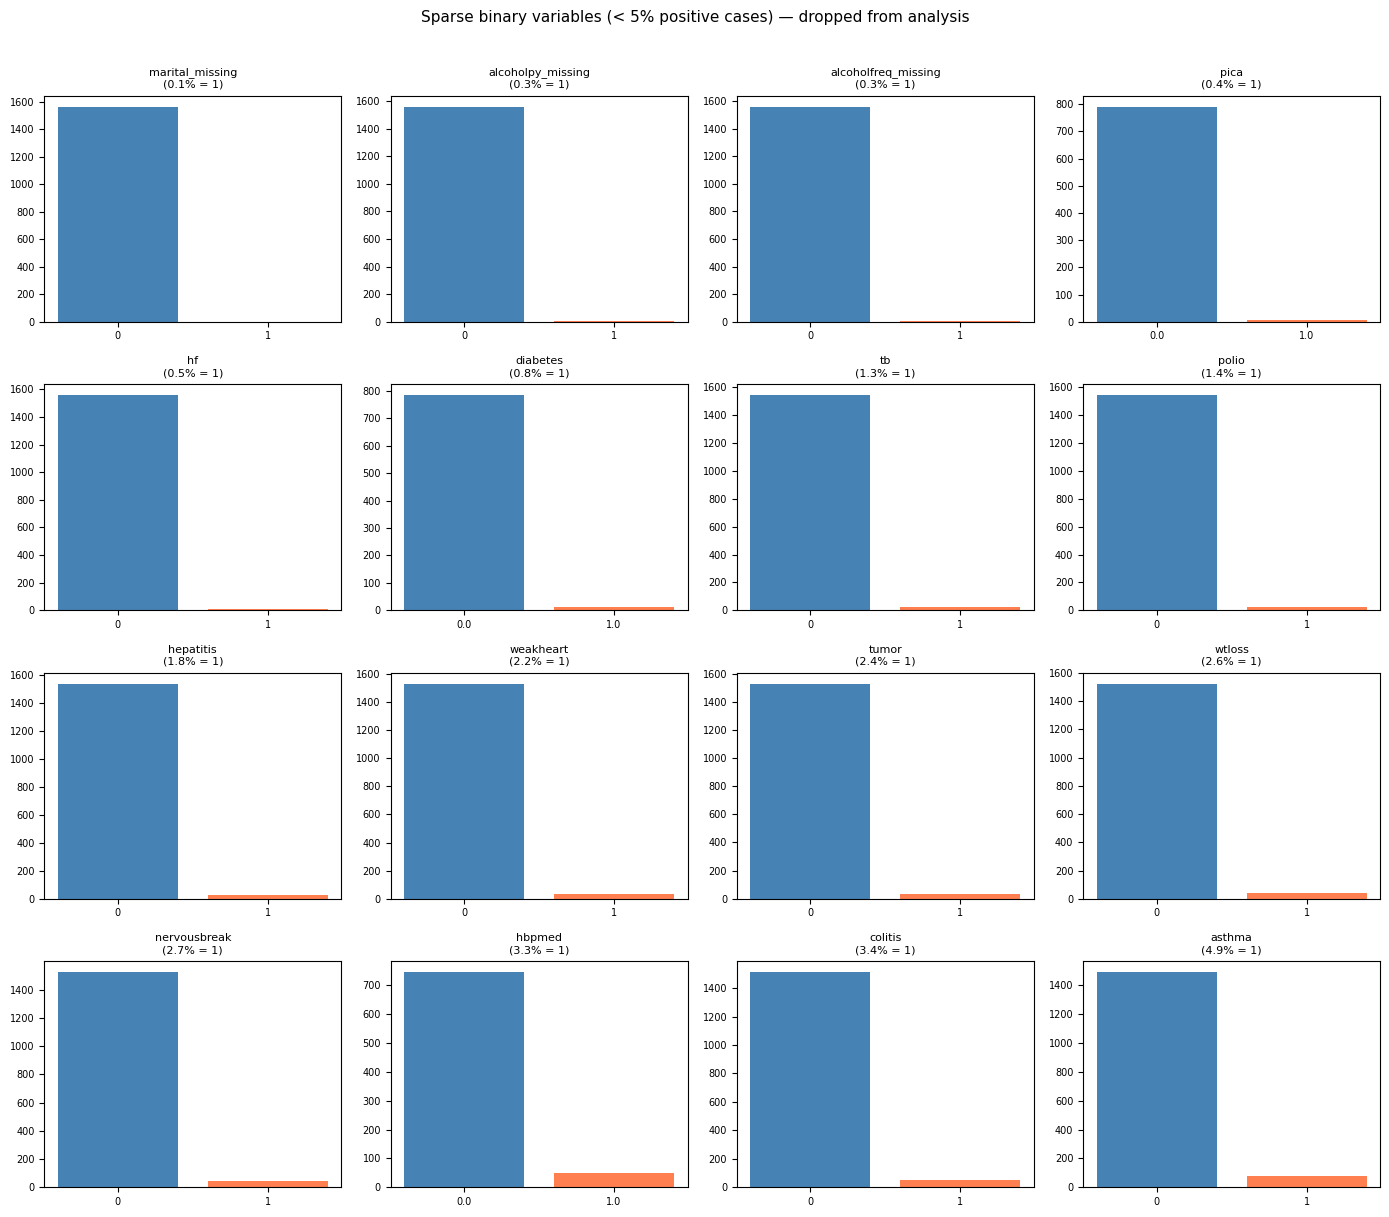

In [11]:
fig, axes = plt.subplots(
    nrows=(len(rare_binary_flagged) + 3) // 4, ncols=4,
    figsize=(14, max(3, 3 * ((len(rare_binary_flagged) + 3) // 4)))
)
axes = axes.flatten()

for i, row in rare_binary_flagged.iterrows():
    var = row["variable"]
    counts = df_clean[var].value_counts().sort_index()
    axes[i].bar(counts.index.astype(str), counts.values, color=["steelblue", "coral"])
    axes[i].set_title(f"{var}\n({row['pct_value_1']:.1f}% = 1)", fontsize=8)
    axes[i].tick_params(labelsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Sparse binary variables (< 5% positive cases) — dropped from analysis",
             fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

These variables are almost entirely zero, including them in the analysis would not provide useful conditioning information and would inflate the number of CI tests in the PC algorithm. We drop them.

#### 1.7.4 Descriptive Summary of the Sample

In [12]:
summary = pd.Series({
    'n': len(df_clean),
    'quit_rate_pct': 100 * df_clean['qsmk'].mean(),
    'mean_age': df_clean['age'].mean(),
    'female_pct': 100 * df_clean['sex'].mean(),
    'black_or_other_pct': 100 * df_clean['race'].mean(),
    'mean_weight_1971': df_clean['wt71'].mean(),
    'mean_weight_change': df_clean['wt82_71'].mean(),
    'mean_cigarettes_per_day': df_clean['smokeintensity'].mean(),
    'mean_years_smoking': df_clean['smokeyrs'].mean(),
    'death_pct': 100 * df_clean['death'].mean()
}).round(2)

summary

n                          1566.00
quit_rate_pct                25.73
mean_age                     43.66
female_pct                   51.34
black_or_other_pct           13.15
mean_weight_1971             70.83
mean_weight_change            2.64
mean_cigarettes_per_day      20.53
mean_years_smoking           24.59
death_pct                    18.58
dtype: float64

A few initial takeaways:

- Around **25.7%** of the sample quit smoking by 1982.
- The average participant is in the mid-40s.
- The average weight gain over the period is positive.
- There is substantial variation in smoking intensity and weight change.

#### 1.7.5 Quitters vs Non-Quitters at Baseline

This comparison is central for causal inference. If people who quit already differ from people who continue smoking at baseline, then a simple comparison of average weight gain will mix the effect of quitting with pre-existing differences between the groups.

In [13]:
quitters = df_clean[df_clean['qsmk'] == 1]
continuers = df_clean[df_clean['qsmk'] == 0]

def mean_sd(x):
    return f"{x.mean():.2f} ({x.std():.2f})"

def pct(x):
    return f"{100 * x.mean():.1f}%"

baseline_table = pd.DataFrame({
    'Variable': [
        'Age', 'Female', 'Black/other race', 'Education (1-5)',
        'Cigarettes/day', 'Years smoking', 'Weight in 1971 (kg)',
        'Exercise (0-2)', 'Daily activity (0-2)',
        'Alcohol frequency (coded scale)', 'Weight loss medication'
    ],
    'Quit smoking (qsmk=1)': [
        mean_sd(quitters['age']), pct(quitters['sex']), pct(quitters['race']),
        mean_sd(quitters['education']), mean_sd(quitters['smokeintensity']),
        mean_sd(quitters['smokeyrs']), mean_sd(quitters['wt71']),
        mean_sd(quitters['exercise']), mean_sd(quitters['active']),
        mean_sd(quitters['alcoholfreq']), pct(quitters['wtloss'])
    ],
    'Continued smoking (qsmk=0)': [
        mean_sd(continuers['age']), pct(continuers['sex']), pct(continuers['race']),
        mean_sd(continuers['education']), mean_sd(continuers['smokeintensity']),
        mean_sd(continuers['smokeyrs']), mean_sd(continuers['wt71']),
        mean_sd(continuers['exercise']), mean_sd(continuers['active']),
        mean_sd(continuers['alcoholfreq']), pct(continuers['wtloss'])
    ]
})

baseline_table

,Variable,Quit smoking (qsmk=1),Continued smoking (qsmk=0)
0,Age,46.17 (12.21),42.79 (11.79)
1,Female,45.4%,53.4%
2,Black/other race,8.9%,14.6%
3,Education (1-5),2.79 (1.28),2.69 (1.15)
4,Cigarettes/day,18.60 (12.40),21.19 (11.48)
5,Years smoking,26.03 (12.74),24.09 (11.71)
6,Weight in 1971 (kg),72.35 (15.63),70.30 (15.18)
7,Exercise (0-2),1.25 (0.71),1.18 (0.74)
8,Daily activity (0-2),0.69 (0.66),0.63 (0.64)
9,Alcohol frequency (coded scale),1.95 (1.31),1.89 (1.29)


The baseline comparison reveals several descriptive differences between individuals who quit smoking and those who did not. On average, quitters appear to be older, to have smoked for a greater number of years, and to have a higher baseline body weight. At the same time, they report slightly lower smoking intensity. These patterns suggest that quitting smoking is not randomly assigned, individuals who quit differ systematically from those who continue even before the outcome is measured.

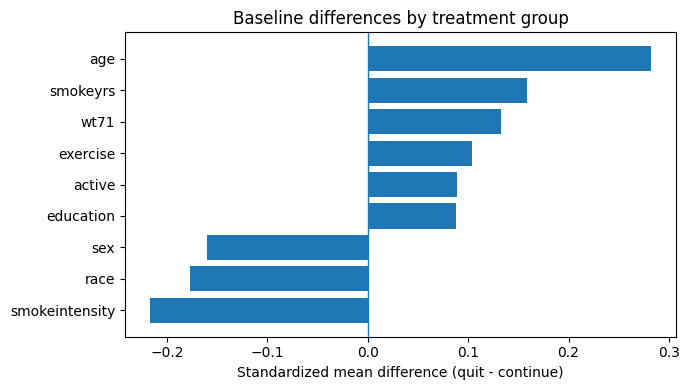

,variable,smd
0,age,0.281981
4,smokeintensity,-0.216675
2,race,-0.176918
1,sex,-0.160129
5,smokeyrs,0.158918
8,wt71,0.133216
6,exercise,0.103586
7,active,0.088714
3,education,0.087897


In [14]:
selected = ['age', 'sex', 'race', 'education', 'smokeintensity', 'smokeyrs', 'exercise', 'active', 'wt71']

rows = []
for v in selected:
    x1 = quitters[v].astype(float)
    x0 = continuers[v].astype(float)
    smd = (x1.mean() - x0.mean()) / np.sqrt((x1.var(ddof=1) + x0.var(ddof=1)) / 2)
    rows.append({'variable': v, 'smd': smd})

smd_df = pd.DataFrame(rows).sort_values('smd')

plt.figure(figsize=(7, 4))
plt.axvline(0, linewidth=1)
plt.barh(smd_df['variable'], smd_df['smd'])
plt.xlabel('Standardized mean difference (quit - continue)')
plt.title('Baseline differences by treatment group')
plt.tight_layout()
plt.show()

smd_df.sort_values('smd', key=np.abs, ascending=False)

#### 1.7.6 Weight Change: Outcome Exploration

We now look at the distribution of the outcome `wt82_71`. The distribution appears approximately bell-shaped, shifted slightly to the right, indicating that weight gain was more common than weight loss over 1971–1982.

count    1566.00
mean        2.64
std         7.88
min       -41.28
25%        -1.48
50%         2.60
75%         6.69
max        48.54
Name: wt82_71, dtype: float64


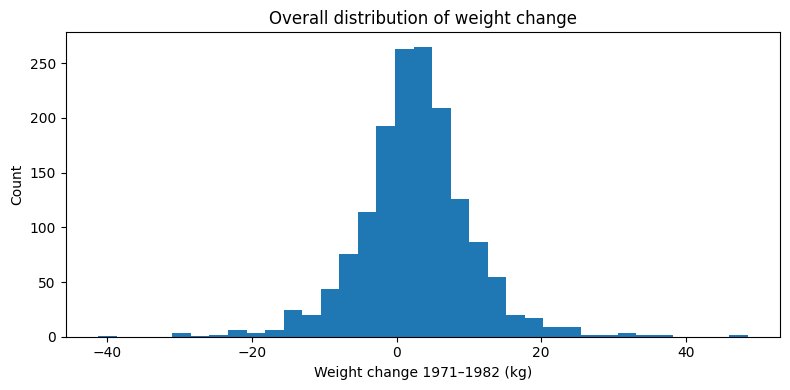

In [15]:
print(df_clean['wt82_71'].describe().round(2))

plt.figure(figsize=(8, 4))
plt.hist(df_clean['wt82_71'], bins=35)
plt.xlabel('Weight change 1971–1982 (kg)')
plt.ylabel('Count')
plt.title('Overall distribution of weight change')
plt.tight_layout()
plt.show()

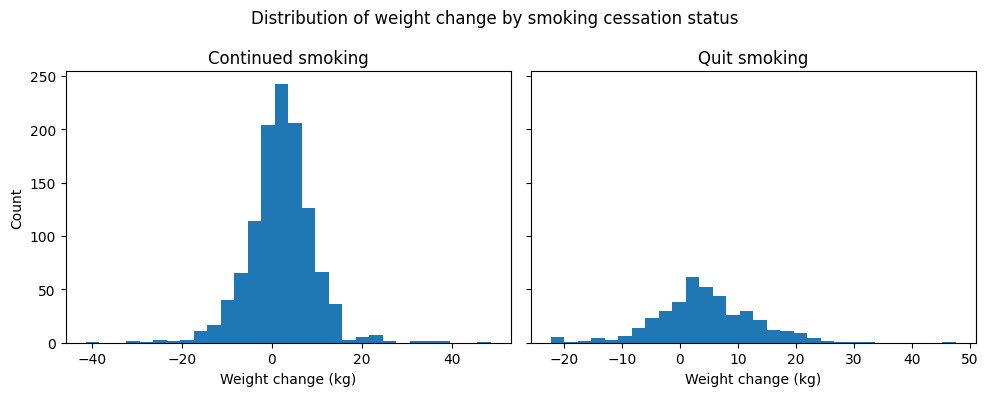

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, q in zip(axes, [0, 1]):
    subset = df_clean.loc[df_clean['qsmk'] == q, 'wt82_71']
    ax.hist(subset, bins=30)
    ax.set_title('Continued smoking' if q == 0 else 'Quit smoking')
    ax.set_xlabel('Weight change (kg)')

axes[0].set_ylabel('Count')
fig.suptitle('Distribution of weight change by smoking cessation status')
fig.tight_layout()
plt.show()

Weight change appears distributed differently across the two groups. For those who continued smoking, the distribution is concentrated nearer to zero, whereas for those who quit it is shifted toward positive values.

In [17]:
weight_change_table = pd.DataFrame({
    'Group': ['Quit smoking', 'Continued smoking'],
    'N': [len(quitters), len(continuers)],
    'Mean weight change (kg)': [quitters['wt82_71'].mean(), continuers['wt82_71'].mean()],
    'Median weight change (kg)': [quitters['wt82_71'].median(), continuers['wt82_71'].median()],
    'SD weight change': [quitters['wt82_71'].std(), continuers['wt82_71'].std()],
    '5th percentile': [quitters['wt82_71'].quantile(0.05), continuers['wt82_71'].quantile(0.05)],
    '95th percentile': [quitters['wt82_71'].quantile(0.95), continuers['wt82_71'].quantile(0.95)]
}).round(2)

weight_change_table

,Group,N,Mean weight change (kg),Median weight change (kg),SD weight change,5th percentile,95th percentile
0,Quit smoking,403,4.53,3.97,8.75,-8.38,19.33
1,Continued smoking,1163,1.98,2.15,7.45,-10.09,12.80


#### 1.7.7 Smoking Behavior Exploration

Baseline smoking intensity also looks somewhat different across the two groups. People who continued smoking seem to be more concentrated at the higher levels of cigarette consumption, while those who later quit appear somewhat more common in the lower to middle part of the distribution. This suggests that the two groups may already differ in their smoking habits before quitting is observed — a key motivation for including smoking history variables in the adjustment set.

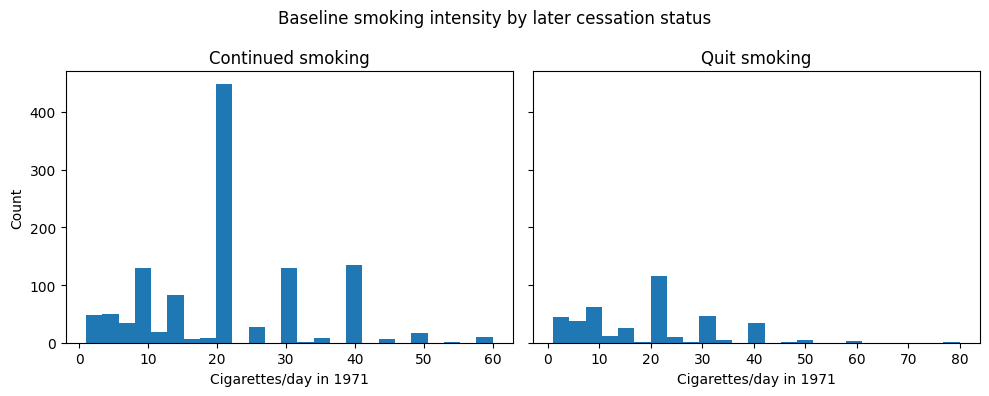

smokeintensity               smokeyrs              
               mean median    std     mean median    std
qsmk                                                    
0             21.19   20.0  11.48    24.09   23.0  11.71
1             18.60   20.0  12.40    26.03   26.0  12.74

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, q in zip(axes, [0, 1]):
    subset = df_clean.loc[df_clean['qsmk'] == q, 'smokeintensity']
    ax.hist(subset, bins=25)
    ax.set_title('Continued smoking' if q == 0 else 'Quit smoking')
    ax.set_xlabel('Cigarettes/day in 1971')

axes[0].set_ylabel('Count')
fig.suptitle('Baseline smoking intensity by later cessation status')
fig.tight_layout()
plt.show()

df_clean.groupby('qsmk')[['smokeintensity', 'smokeyrs']].agg(['mean', 'median', 'std']).round(2)

#### 1.7.8 EDA Conclusions

The exploratory analysis highlights several important issues. The data contain both explicit and coded missing values that need careful handling. Descriptively, individuals who quit smoking gain more weight than those who continue. At the same time, quitters and non-quitters differ at baseline in age, smoking history, baseline weight, and smoking intensity. These baseline differences confirm that quitting is not randomly assigned, so crude group comparisons cannot be interpreted as causal effects. The EDA guided is with the subsequent causal analysis, particularly the choice of which variables to include in the adjustment set.

## 2. Results

### 2.1 Structure Learning with the PC Algorithm

We use the PC algorithm as an exploratory tool to inform the adjustment set. The goal is to identify which baseline variables are conditionally dependent on treatment or outcome, and to detect colliders that would make certain adjustments harmful. We use the KCI (Kernel CI) test as our main CI test because it makes no Gaussianity or linearity assumptions and handles the mixed continuous/binary nature of our data correctly.

Three key design choices we made during the analysis are: (1) we harmonize coded missingness before any CI tests so the algorithm sees real missing values, (2) we restrict the variable set to plausible pre-treatment confounders to avoid the combinatorial explosion of CI tests, and (3) we impose temporal background knowledge so the algorithm cannot orient edges against the known study timeline.

#### 2.1.1 Setup and Variable Selection

In [19]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from causallearn.search.ConstraintBased.PC import pc
from causallearn.utils.cit import kci
from causallearn.utils.GraphUtils import GraphUtils
from causallearn.utils.PCUtils.BackgroundKnowledge import BackgroundKnowledge
from causallearn.graph.GraphNode import GraphNode
from IPython.display import Image, display

np.random.seed(42)

In [20]:
project_dir = Path.cwd()
data_dir = project_dir / "data"

df = pd.read_csv(data_dir / "nhefs_complete.csv")
codebook = pd.read_csv(data_dir / "nhefs_codebook.csv")

We drop identifiers, post-treatment variables, instruments, rare conditions, and heavily missing variables. We also keep only one alcohol variable (`alcoholpy`) since the four alcohol variables are correlated refinements of the same lifestyle signal.

| Category | Dropped | Reason |
|---|---|---|
| Identifiers | seqn, id | No causal content |
| Post-treatment mortality | death, yrdth, modth, dadth | Conditioning on post-treatment descendants opens collider bias paths |
| Post-treatment measures | sbp, dbp, wt82, smkintensity82_71 | Measured after the treatment window or used to compute the outcome |
| Instruments | school, price/tax variables, hightax82 | Affect treatment but have no direct effect on weight, including them amplifies bias |
| Rare conditions | tb, hf, polio, hepatitis, pica | Fewer than 20 cases; CI tests lack power |
| Heavy missingness | boweltrouble, diabetes, hbp, hbpmed, birthcontrol | Over 50% missing with no structural explanation |
| Pregnancies | pregnancies | 55% missing; cannot distinguish zero pregnancies from unknown, dropped entirely |
| Miscellaneous | birthplace, censored, older | Derived indicators with no independent causal role |

In [21]:
pc_vars = [
    'age', 'sex', 'race', 'education', 'income', 'marital', 'wt71',
    'smokeintensity', 'smokeyrs', 'exercise', 'active', 'cholesterol', 'bronch',
    'alcoholpy', 'qsmk', 'wt82_71'
]

y = df['wt82_71'].copy()
df_sel = df[pc_vars].copy()

print(f"Retained {df_sel.shape[1]} variables:")
print(list(df_sel.columns))

Retained 16 variables:
['age', 'sex', 'race', 'education', 'income', 'marital', 'wt71', 'smokeintensity', 'smokeyrs', 'exercise', 'active', 'cholesterol', 'bronch', 'alcoholpy', 'qsmk', 'wt82_71']


#### 2.1.2 Missing Data Handling

We harmonize coded missingness before running PC. NHEFS uses numeric codes like `2 = MISSING` and `marital = 8` that would otherwise be treated as real observations.

In [22]:
codebook["variable"] = codebook["variable"].replace({
    "bithcontrol": "birthcontrol",
    "smkintensity 82_71": "smkintensity82_71"
})

df_harmonized = df_sel.copy()

mask_2_missing = codebook["description"].str.contains(
    r"2\s*:\s*MISSING", case=False, na=False, regex=True
)
vars_2_missing = codebook.loc[mask_2_missing, "variable"].tolist()
vars_2_missing = [c for c in vars_2_missing if c in df_harmonized.columns]

special_missing_codes = {c: 2 for c in vars_2_missing}
if "marital" in df_harmonized.columns:
    special_missing_codes["marital"] = 8
if "alcoholfreq" in df_harmonized.columns:
    special_missing_codes["alcoholfreq"] = 5

for var, miss_code in special_missing_codes.items():
    df_harmonized[var] = df_harmonized[var].replace(miss_code, np.nan)

miss = df_harmonized.isnull().sum().reset_index()
miss.columns = ['variable', 'n_missing']
miss['pct_missing'] = (miss['n_missing'] / len(df_harmonized) * 100).round(2)
miss = miss.sort_values('n_missing', ascending=False)
print(miss[miss['n_missing'] > 0].to_string(index=False))

   variable  n_missing  pct_missing
     income         59         3.77
cholesterol         16         1.02
  alcoholpy          5         0.32
    marital          1         0.06


We test whether missingness is MCAR by checking its association with treatment and outcome.

In [23]:
for var in ['income', 'cholesterol', 'alcoholpy', 'marital']:
    if var not in df_harmonized.columns:
        continue
    missing_flag = df_harmonized[var].isnull().astype(int)
    ct = pd.crosstab(missing_flag, df_harmonized['qsmk'])
    chi2_stat, p, _, _ = stats.chi2_contingency(ct)
    obs_mean = y[df_harmonized[var].notna()].mean()
    mis_mean = y[df_harmonized[var].isna()].mean()
    print(f"{var}:")
    print(f"  missingness vs qsmk: chi2={chi2_stat:.3f}, p={p:.4f}")
    print(f"  wt82_71 mean: observed: {obs_mean:.2f}, missing: {mis_mean:.2f}\n")

income:
  missingness vs qsmk: chi2=6.374, p=0.0116
  wt82_71 mean: observed: 2.61, missing: 3.31

cholesterol:
  missingness vs qsmk: chi2=0.864, p=0.3525
  wt82_71 mean: observed: 2.63, missing: 3.31

alcoholpy:
  missingness vs qsmk: chi2=0.000, p=1.0000
  wt82_71 mean: observed: 2.64, missing: 1.34

marital:
  missingness vs qsmk: chi2=0.308, p=0.5787
  wt82_71 mean: observed: 2.64, missing: 5.33



Income is not MCAR (p=0.01). People with missing income are more likely to have quit and gained more weight. Cholesterol is borderline MAR. Alcoholpy and marital are effectively MCAR with trivial missingness.

We decided to delete these observations rather than impute them. Imputation would introduce artificial conditional dependencies that KCI would pick up as spurious edges. Since KCI does not support NaN natively, deletion is the only viable option. We lose fewer than 5% of observations, and the bias from this is likely negligible.

In [24]:
df_for_pc = df_harmonized.dropna()
print(f"Sample size after dropping incomplete rows: {len(df_for_pc)} "
      f"(lost {len(df_harmonized) - len(df_for_pc)})")

Sample size after dropping incomplete rows: 1486 (lost 80)


#### 2.1.3 Gaussian Linearity Diagnostics

Before running PC we check whether the Gaussian linearity assumption behind Fisher-z would be defensible. This motivates our choice of KCI as the CI test.

In [25]:
continuous_vars = [v for v in ['age', 'cholesterol', 'smokeintensity', 'smokeyrs', 'wt71']
                   if v in df_for_pc.columns]

norm_results = []
for c in continuous_vars:
    x = df_for_pc[c].dropna().values
    sw_stat, sw_p = stats.shapiro(x[:5000])
    sk = stats.skew(x)
    ku = stats.kurtosis(x)
    norm_results.append({
        'variable': c, 'shapiro_p': f"{sw_p:.2e}",
        'skewness': round(sk, 2), 'excess_kurtosis': round(ku, 2),
        'flag': '***' if (abs(sk) > 1 or ku > 2) else ''
    })

norm_df = pd.DataFrame(norm_results)
print(norm_df.to_string(index=False))

      variable shapiro_p  skewness  excess_kurtosis flag
           age  5.08e-18      0.25            -0.85     
   cholesterol  3.78e-12      0.54             0.60     
smokeintensity  1.08e-26      0.76             0.70     
      smokeyrs  5.99e-14      0.36            -0.51     
          wt71  6.66e-18      0.78             1.01     


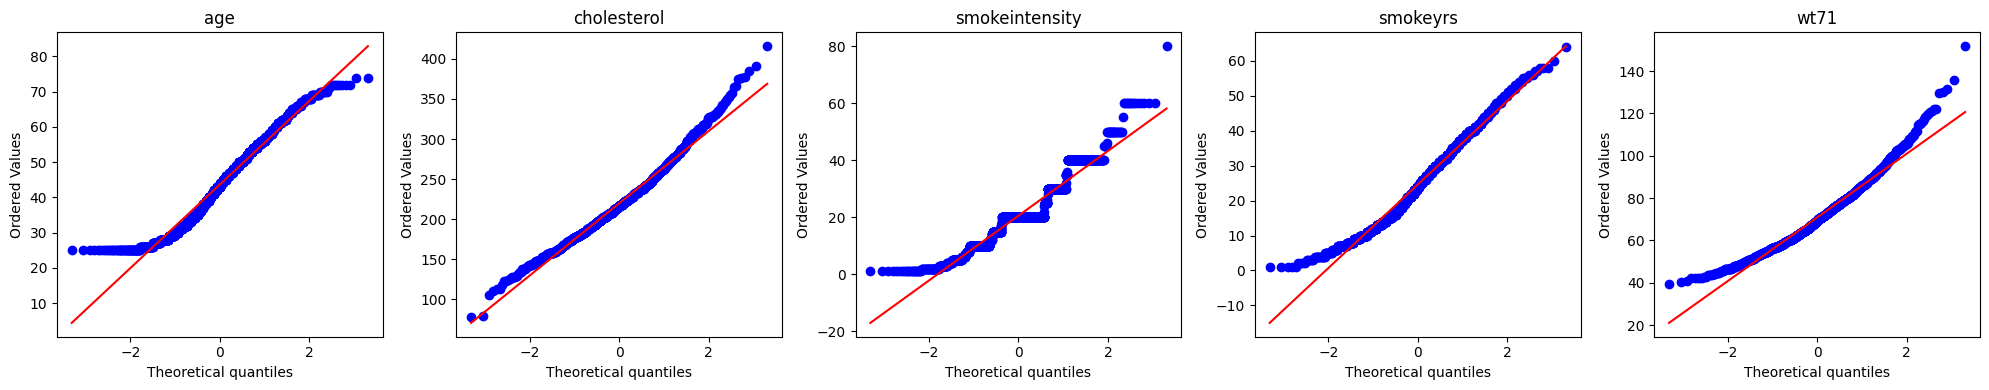

In [26]:
qq_vars = continuous_vars
fig, axes = plt.subplots(1, len(qq_vars), figsize=(4 * len(qq_vars), 4))
for ax, v in zip(axes, qq_vars):
    stats.probplot(df_for_pc[v].dropna().values, dist='norm', plot=ax)
    ax.set_title(v)
plt.tight_layout()
plt.show()

In [27]:
cont_data = df_for_pc[continuous_vars].dropna()
pearson_corr = cont_data.corr(method='pearson')
spearman_corr = cont_data.corr(method='spearman')
diff = (pearson_corr - spearman_corr).abs()

pairs = []
cols = diff.columns.tolist()
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        pairs.append({
            'var1': cols[i], 'var2': cols[j],
            'pearson': round(pearson_corr.iloc[i, j], 3),
            'spearman': round(spearman_corr.iloc[i, j], 3),
            'abs_diff': round(diff.iloc[i, j], 3)
        })

lin_df = pd.DataFrame(pairs).sort_values('abs_diff', ascending=False)
print(lin_df.head(10).to_string(index=False))

          var1           var2  pearson  spearman  abs_diff
           age           wt71    0.016     0.050     0.034
   cholesterol       smokeyrs    0.207     0.239     0.033
      smokeyrs           wt71    0.053     0.082     0.029
           age    cholesterol    0.282     0.301     0.019
   cholesterol           wt71    0.120     0.136     0.016
smokeintensity           wt71    0.100     0.114     0.014
           age       smokeyrs    0.868     0.878     0.010
smokeintensity       smokeyrs    0.052     0.059     0.007
   cholesterol smokeintensity    0.008     0.004     0.004
           age smokeintensity   -0.042    -0.043     0.001


The departures from normality are mild. No variable exceeds |skewness| > 1 or excess kurtosis > 2, and all Pearson–Spearman differences are below 0.035. However, we still use KCI as our single CI test rather than Fisher-z. The reason is not the continuous variable behavior, which is acceptable, but the fact that roughly half our variables are binary, and Fisher-z is the wrong test for those regardless of how well-behaved the continuous variables are. KCI handles both types correctly without any distributional assumptions.

#### 2.1.4 Temporal Background Knowledge

We encode what we know from the study design. All baseline covariates were measured in 1971, treatment occurred between 1971–1982, and the outcome was measured in 1982. We also protect sex and race as fixed-at-birth variables, no other variable in the dataset can cause them.

In [29]:
def build_background_knowledge(pretreat, treatment='qsmk', outcome='wt82_71',
                               require_treatment_to_outcome=False,
                               fixed_vars=None):
    bk = BackgroundKnowledge()
    nodes = {v: GraphNode(v) for v in pretreat + [treatment, outcome]}
    for v in pretreat:
        bk.add_node_to_tier(nodes[v], 0)
    bk.add_node_to_tier(nodes[treatment], 1)
    bk.add_node_to_tier(nodes[outcome], 2)
    if require_treatment_to_outcome:
        bk.add_required_by_node(nodes[treatment], nodes[outcome])
    if fixed_vars:
        for fixed in fixed_vars:
            if fixed not in nodes:
                continue
            for v in pretreat:
                if v != fixed:
                    bk.add_forbidden_by_node(nodes[v], nodes[fixed])
    return bk

pretreat = [v for v in pc_vars if v not in ['qsmk', 'wt82_71']]
bk = build_background_knowledge(pretreat, treatment='qsmk', outcome='wt82_71',
                                 fixed_vars=['sex', 'race'])

print(f"Baseline covariates (tier 0): {pretreat}")
print("Treatment (tier 1): qsmk")
print("Outcome (tier 2): wt82_71")
print("Fixed at birth (no incoming edges): sex, race")

Baseline covariates (tier 0): ['age', 'sex', 'race', 'education', 'income', 'marital', 'wt71', 'smokeintensity', 'smokeyrs', 'exercise', 'active', 'cholesterol', 'bronch', 'alcoholpy']
Treatment (tier 1): qsmk
Outcome (tier 2): wt82_71
Fixed at birth (no incoming edges): sex, race


#### 2.1.5 PC Algorithm with KCI — Main Result

We run the PC algorithm with KCI as the CI test. KCI scales O(n³) so this may take several minutes.

In [ ]:
df_kci = df_for_pc[pc_vars].dropna()
kci_data = df_kci.values.astype(float)

print(f"KCI sample size: {len(df_kci)} (complete cases)")

cg_kci = pc(
    kci_data,
    alpha=0.05,
    indep_test=kci,
    stable=True,
    background_knowledge=bk,
    node_names=pc_vars,
)

In [ ]:
pdy_kci = GraphUtils.to_pydot(cg_kci.G, labels=pc_vars)
pdy_kci.write_png("../outputs/figures/cpdag_kci_05_tiered.png")
display(Image("../outputs/figures/cpdag_kci_05_tiered.png"))

In [ ]:
def extract_edges(cg, labels, nodes_of_interest):
    g = cg.G.graph
    edges = []
    for node in nodes_of_interest:
        if node not in labels:
            continue
        idx = labels.index(node)
        for j in range(len(labels)):
            if j == idx:
                continue
            if g[idx, j] == -1 and g[j, idx] == 1:
                edges.append(f"{labels[idx]} -> {labels[j]}")
            elif g[idx, j] == 1 and g[j, idx] == -1:
                edges.append(f"{labels[j]} -> {labels[idx]}")
            elif g[idx, j] == -1 and g[j, idx] == -1:
                edges.append(f"{labels[idx]} -- {labels[j]}")
            elif g[idx, j] != 0 or g[j, idx] != 0:
                edges.append(f"{labels[idx]} ? {labels[j]}")
    return sorted(set(edges))

e_kci = extract_edges(cg_kci, pc_vars, ['qsmk', 'wt82_71'])
print("KCI alpha=0.05 — edges involving qsmk or wt82_71:")
for e in e_kci:
    print(f"  {e}")
if not e_kci:
    print("  (no edges involving qsmk or wt82_71)")

The learned graph is consistent with domain knowledge in its main features. `smokeintensity` and `sex` are direct causes of `qsmk`, and `sex`, `smokeyrs`, `income`, `education`, and `exercise` are direct causes of `wt82_71`. The treatment edge `qsmk → wt82_71` is correctly oriented and survives conditioning on all baseline covariates, which supports the existence of a treatment-outcome association after adjustment.

> **Reminder:** The empirical check of conditional ignorability and positivity referenced in Section 1.4 is completed in Sections 2.1.6 and 3.1 respectively.

#### 2.1.6 Adjustment Set and Conditional Ignorability Check

We adjust for all baseline covariates that appear connected to either treatment or outcome in the graph, plus domain-knowledge additions for variables that are plausible confounders despite being isolated. We exclude variables that the graph found no connections for and for which domain knowledge does not strongly motivate inclusion.

In [33]:
adjustment_set = [
    'sex', 'race', 'age', 'income', 'education', 'marital',
    'smokeintensity', 'smokeyrs', 'wt71',
    'exercise', 'active', 'alcoholpy', 'cholesterol', 'bronch'
]

print(f"Adjustment set ({len(adjustment_set)} variables):")
print(adjustment_set)

Adjustment set (14 variables):
['sex', 'race', 'age', 'income', 'education', 'marital', 'smokeintensity', 'smokeyrs', 'wt71', 'exercise', 'active', 'alcoholpy', 'cholesterol', 'bronch']


### 3.1 Positivity Check

We verify the positivity assumption by fitting a logistic regression propensity score and inspecting the overlap between treated and untreated distributions. Violations appear as scores near 0 or 1.

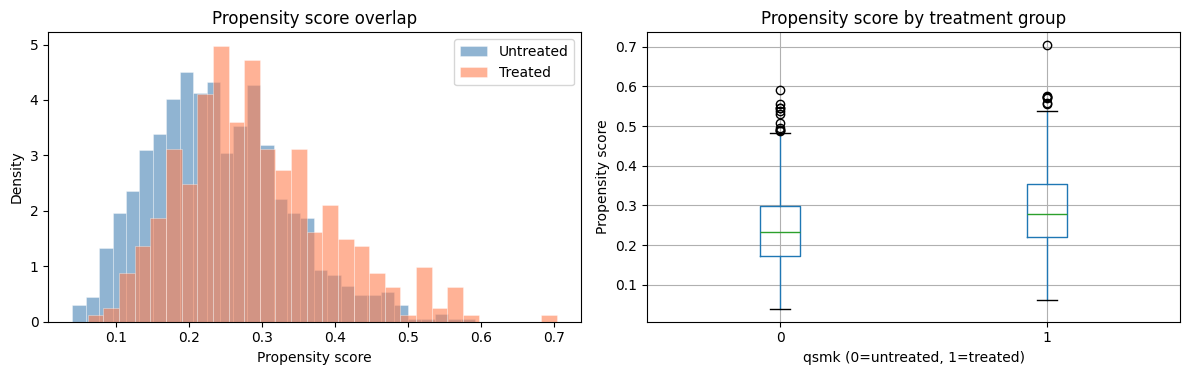

Propensity score summary by treatment group:
       count   mean    std    min    25%    50%    75%    max
qsmk                                                         
0     1110.0  0.240  0.093  0.040  0.172  0.232  0.298  0.591
1      376.0  0.291  0.103  0.061  0.220  0.278  0.354  0.703

Scores < 0.05: 2 (0.1%)
Scores > 0.95: 0 (0.0%)


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

df_pos = df_for_pc[adjustment_set + ['qsmk']].dropna()

X = df_pos[adjustment_set].values
y_pos = df_pos['qsmk'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_scaled, y_pos)
ps = lr.predict_proba(X_scaled)[:, 1]

df_pos = df_pos.copy()
df_pos['propensity_score'] = ps

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for val, label, color in [(0, 'Untreated', 'steelblue'), (1, 'Treated', 'coral')]:
    axes[0].hist(ps[y_pos == val], bins=30, alpha=0.6, label=label, color=color,
                 density=True, edgecolor='white', linewidth=0.4)
axes[0].set_xlabel('Propensity score')
axes[0].set_ylabel('Density')
axes[0].set_title('Propensity score overlap')
axes[0].legend()

df_pos.boxplot(column='propensity_score', by='qsmk', ax=axes[1])
axes[1].set_xlabel('qsmk (0=untreated, 1=treated)')
axes[1].set_ylabel('Propensity score')
axes[1].set_title('Propensity score by treatment group')
plt.suptitle('')
plt.tight_layout()
plt.show()

print("Propensity score summary by treatment group:")
print(df_pos.groupby('qsmk')['propensity_score'].describe().round(3))

n_near_zero = (ps < 0.05).sum()
n_near_one = (ps > 0.95).sum()
print(f"\nScores < 0.05: {n_near_zero} ({n_near_zero/len(ps)*100:.1f}%)")
print(f"Scores > 0.95: {n_near_one} ({n_near_one/len(ps)*100:.1f}%)")

The positivity assumption holds. Propensity scores range from 0.05 to 0.70 with substantial overlap between treated and untreated groups across the full support. Only two observations (0.1%) fall below the 0.05 threshold and none above 0.95, indicating near-perfect positivity with negligible violations.

### 3.2 Causal Effect Estimation

We estimate the ATE using two methods: PLR via DoubleML and IPW with a calibrated XGBoost propensity score. Both use the same adjustment set identified from the PC graph.

In [35]:
import doubleml
from doubleml import DoubleMLData, DoubleMLPLR
from xgboost import XGBClassifier, XGBRegressor
from sklearn.model_selection import cross_val_predict
from sklearn.calibration import CalibratedClassifierCV
from statsmodels.stats.outliers_influence import variance_inflation_factor

df_est = df_for_pc[adjustment_set + ['qsmk', 'wt82_71']].dropna().copy()

X = df_est[adjustment_set].values
T = df_est['qsmk'].values
Y = df_est['wt82_71'].values

print(f"Estimation sample: {len(df_est)} observations")
print(f"Treatment prevalence: {T.mean():.3f}")
print(f"Outcome mean: {Y.mean():.3f}, SD: {Y.std():.3f}")

Estimation sample: 1486 observations
Treatment prevalence: 0.253
Outcome mean: 2.611, SD: 7.829


#### 3.2.1 XGBoost Hyperparameter Tuning

Before fitting the final models, we tune the XGBoost hyperparameters for both the outcome model (used in PLR) and the propensity score model (used in IPW). We use a grid search with 5-fold cross-validation, optimizing RMSE for the outcome model and log-loss for the propensity model.

In [36]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, KFold
from sklearn.metrics import make_scorer

param_grid_reg = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'reg_lambda': [1, 2, 5],
}

param_grid_clf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4],
    'learning_rate': [0.01, 0.05],
    'subsample': [0.8, 1.0],
    'min_child_weight': [10, 20],
    'reg_lambda': [2, 5],
}

print("Tuning outcome model (XGBRegressor) for PLR...")
xgb_reg_base = XGBRegressor(random_state=42, verbosity=0)
gs_reg = GridSearchCV(
    xgb_reg_base, param_grid_reg,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1, verbose=0
)
gs_reg.fit(X, Y)
best_reg_params = gs_reg.best_params_
print(f"Best outcome model params: {best_reg_params}")
print(f"Best CV RMSE: {-gs_reg.best_score_:.3f}")

Tuning outcome model (XGBRegressor) for PLR...
Best outcome model params: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200, 'reg_lambda': 1, 'subsample': 0.8}
Best CV RMSE: 7.597


In [37]:
print("Tuning propensity model (XGBClassifier) for IPW...")
xgb_clf_base = XGBClassifier(random_state=42, verbosity=0, eval_metric='logloss')
gs_clf = GridSearchCV(
    xgb_clf_base, param_grid_clf,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='neg_log_loss',
    n_jobs=-1, verbose=0
)
gs_clf.fit(X, T)
best_clf_params = gs_clf.best_params_
print(f"Best propensity model params: {best_clf_params}")
print(f"Best CV log-loss: {-gs_clf.best_score_:.3f}")

Tuning propensity model (XGBClassifier) for IPW...
Best propensity model params: {'learning_rate': 0.01, 'max_depth': 3, 'min_child_weight': 10, 'n_estimators': 300, 'reg_lambda': 5, 'subsample': 1.0}
Best CV log-loss: 0.546


We use the tuned hyperparameters in all downstream models.

#### 3.2.2 Partially Linear Regression (PLR)

We fit the PLR using DoubleML with 5-fold cross-fitting and 3 repetitions to reduce Monte Carlo variance. The outcome nuisance model uses the tuned XGBRegressor and the treatment nuisance model uses the tuned XGBClassifier.

In [38]:
dml_data = DoubleMLData.from_arrays(x=X, y=Y, d=T)

ml_l = XGBRegressor(**best_reg_params, random_state=42, verbosity=0)
ml_m = XGBClassifier(**best_clf_params, random_state=42, verbosity=0, eval_metric='logloss')

plr = DoubleMLPLR(dml_data, ml_l=ml_l, ml_m=ml_m, n_folds=5, n_rep=3)
plr.fit()

print("── PLR Results ──")
print(plr.summary)
print(f"\nATE: {plr.coef[0]:.3f}")
print(f"95% CI: [{plr.confint().iloc[0,0]:.3f}, {plr.confint().iloc[0,1]:.3f}]")

── PLR Results ──
       coef   std err         t         P>|t|     2.5 %    97.5 %
d  3.296979  0.492788  6.690462  2.224664e-11  2.331132  4.262826

ATE: 3.297
95% CI: [2.331, 4.263]


We check the PLR assumptions via residual plots.

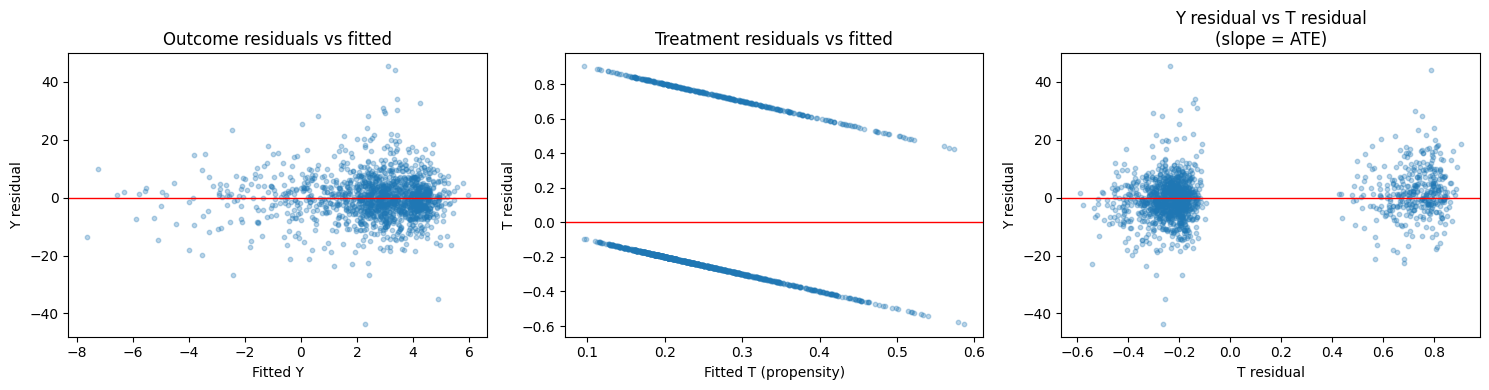

In [39]:
ml_l_cv = XGBRegressor(**best_reg_params, random_state=42, verbosity=0)
ml_m_cv = XGBClassifier(**best_clf_params, random_state=42, verbosity=0, eval_metric='logloss')

Y_hat = cross_val_predict(ml_l_cv, X, Y, cv=5)
T_hat = cross_val_predict(ml_m_cv, X, T, cv=5, method='predict_proba')[:, 1]

Y_resid = Y - Y_hat
T_resid = T - T_hat

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(Y_hat, Y_resid, alpha=0.3, s=10)
axes[0].axhline(0, color='red', linewidth=1)
axes[0].set_xlabel('Fitted Y'); axes[0].set_ylabel('Y residual')
axes[0].set_title('Outcome residuals vs fitted')

axes[1].scatter(T_hat, T_resid, alpha=0.3, s=10)
axes[1].axhline(0, color='red', linewidth=1)
axes[1].set_xlabel('Fitted T (propensity)'); axes[1].set_ylabel('T residual')
axes[1].set_title('Treatment residuals vs fitted')

axes[2].scatter(T_resid, Y_resid, alpha=0.3, s=10)
axes[2].axhline(0, color='red', linewidth=1)
axes[2].set_xlabel('T residual'); axes[2].set_ylabel('Y residual')
axes[2].set_title('Y residual vs T residual\n(slope = ATE)')

plt.tight_layout()
plt.savefig('../outputs/figures/plr_residuals.png', dpi=150, bbox_inches='tight')
plt.show()

**PLR Assumption Checks**

**Residual plots.** The outcome residuals (left panel) are centered around zero with no systematic pattern against fitted values. The XGBoost outcome model is not making directional errors anywhere in the covariate space. The treatment residuals (middle panel) show the pattern of a binary outcome: the upper band is $1 - \hat{p}$ for treated individuals and the lower band is $0 - \hat{p}$ for untreated ones. We conclude this to be an expected behavior for a binary treatment and is not a violation. The right panel shows the partialled-out residuals plotted against each other, the slight positive slope is the PLR estimate of the ATE, and the cloud is centered around zero with no strong nonlinear pattern, which supports the partial linearity assumption.

#### 3.2.3 Inverse Probability Weighting (IPW)

We estimate the propensity score using the tuned XGBClassifier with Platt scaling calibration to ensure well-calibrated probability estimates. We use stabilized weights to reduce variance, and bootstrap confidence intervals.

In [41]:
xgb_base = XGBClassifier(
    **best_clf_params,
    random_state=42, verbosity=0, eval_metric='logloss'
)
ps_model = CalibratedClassifierCV(xgb_base, method='sigmoid', cv=5)
ps_cv = cross_val_predict(ps_model, X, T, cv=5, method='predict_proba')[:, 1]

p_t = T.mean()
weights = np.where(T == 1, p_t / ps_cv, (1 - p_t) / (1 - ps_cv))

ate_ipw = (np.mean(weights * Y * T) / np.mean(weights * T) -
           np.mean(weights * Y * (1-T)) / np.mean(weights * (1-T)))

np.random.seed(42)
n_boot = 1000
boot_ates = []
n = len(Y)
for _ in range(n_boot):
    idx = np.random.choice(n, n, replace=True)
    w_b, T_b, Y_b = weights[idx], T[idx], Y[idx]
    ate_b = (np.mean(w_b * Y_b * T_b) / np.mean(w_b * T_b) -
             np.mean(w_b * Y_b * (1-T_b)) / np.mean(w_b * (1-T_b)))
    boot_ates.append(ate_b)

ci_low, ci_high = np.percentile(boot_ates, [2.5, 97.5])

print("── IPW Results ──")
print(f"ATE: {ate_ipw:.3f}")
print(f"95% Bootstrap CI: [{ci_low:.3f}, {ci_high:.3f}]")

── IPW Results ──
ATE: 2.949
95% Bootstrap CI: [1.922, 3.901]


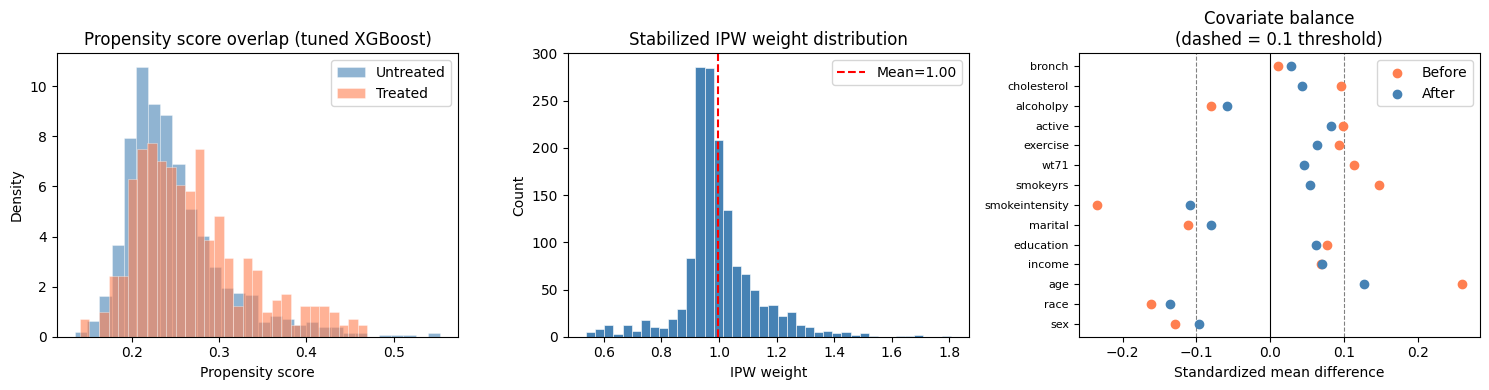

Covariate balance (SMD < 0.1 = balanced):
      variable  smd_before  smd_after balanced
           age       0.260      0.127        ✗
smokeintensity      -0.235     -0.109        ✗
          race      -0.162     -0.135        ✗
      smokeyrs       0.148      0.054        ✓
           sex      -0.129     -0.097        ✓
          wt71       0.114      0.046        ✓
       marital      -0.111     -0.080        ✓
        active       0.099      0.082        ✓
   cholesterol       0.096      0.043        ✓
      exercise       0.094      0.064        ✓
     alcoholpy      -0.080     -0.058        ✓
     education       0.076      0.062        ✓
        income       0.069      0.070        ✓
        bronch       0.011      0.028        ✓

Extreme weights (>10): 0


In [42]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for val, label, color in [(0, 'Untreated', 'steelblue'), (1, 'Treated', 'coral')]:
    axes[0].hist(ps_cv[T == val], bins=30, alpha=0.6, label=label,
                 color=color, density=True, edgecolor='white', linewidth=0.4)
axes[0].set_xlabel('Propensity score')
axes[0].set_ylabel('Density')
axes[0].set_title('Propensity score overlap (tuned XGBoost)')
axes[0].legend()

axes[1].hist(weights, bins=40, edgecolor='white', linewidth=0.4, color='steelblue')
axes[1].axvline(weights.mean(), color='red', linestyle='--',
                label=f'Mean={weights.mean():.2f}')
axes[1].set_xlabel('IPW weight'); axes[1].set_ylabel('Count')
axes[1].set_title('Stabilized IPW weight distribution')
axes[1].legend()

smd_before, smd_after = [], []
for j in range(X.shape[1]):
    x = X[:, j]
    s = x.std()
    smd_before.append((x[T==1].mean() - x[T==0].mean()) / s if s > 0 else 0)
    m1w = np.average(x[T==1], weights=weights[T==1])
    m0w = np.average(x[T==0], weights=weights[T==0])
    smd_after.append((m1w - m0w) / s if s > 0 else 0)

y_pos_vars = range(len(adjustment_set))
axes[2].scatter(smd_before, y_pos_vars, color='coral', label='Before', zorder=3)
axes[2].scatter(smd_after, y_pos_vars, color='steelblue', label='After', zorder=3)
axes[2].axvline(0, color='black', linewidth=0.8)
axes[2].axvline(0.1, color='gray', linewidth=0.8, linestyle='--')
axes[2].axvline(-0.1, color='gray', linewidth=0.8, linestyle='--')
axes[2].set_yticks(list(y_pos_vars))
axes[2].set_yticklabels(adjustment_set, fontsize=8)
axes[2].set_xlabel('Standardized mean difference')
axes[2].set_title('Covariate balance\n(dashed = 0.1 threshold)')
axes[2].legend()

plt.tight_layout()
plt.savefig('../outputs/figures/ipw_checks.png', dpi=150, bbox_inches='tight')
plt.show()

balance_df = pd.DataFrame({
    'variable': adjustment_set,
    'smd_before': [round(s, 3) for s in smd_before],
    'smd_after': [round(s, 3) for s in smd_after],
    'balanced': ['✓' if abs(s) < 0.1 else '✗' for s in smd_after]
}).sort_values('smd_before', key=abs, ascending=False)

print("Covariate balance (SMD < 0.1 = balanced):")
print(balance_df.to_string(index=False))
print(f"\nExtreme weights (>10): {(weights > 10).sum()}")

**IPW Assumption Checks**

**Propensity score overlap.** The two distributions overlap across most of the support, but the overlap is imperfect. The untreated group is concentrated around 0.20-0.3 with a sharp peak, while the treated group is more spread out and extends further into the right tail above 0.40. This means that at the extremes of the propensity score distribution: very low scores (below ~0.17) and higher scores (above ~0.45), one group dominates and counterfactual comparisons rely on limited data. In our opinion, this is a mild overlap concern rather than a full positivity violation, but it does mean that IPW estimates in these regions are less reliable and contribute more uncertainty to the final ATE. The stabilized weights partially compensate for this, as seen in the tight weight distribution, but the residual imbalance on `smokeintensity`, `age`, `race` and `sex` in the balance plot reflects the same underlying issue.

**Weight distribution.** The stabilized IPW weights are tightly concentrated around their mean of 1.00, with a maximum of approximately 1.8 and no extreme observations. We think this is a good result, extreme weights (which would appear as a long right tail) inflate variance and signal near-positivity violations. No truncation is needed here.

**Covariate balance.** After weighting, most variables move closer to zero standardized mean difference. Variables like `smokeintensity`, `age`, `race`, `wt71`, and `smokeyrs` remain somewhat outside the threshold even after weighting.We think that this persistent imbalance may reflect genuine structural differences between quitters and non-quitters in their smoking history and demographics that no propensity score model can fully resolve through reweighting alone. This is a known limitation of IPW in smoking cessation studies and is one reason we also report the PLR estimate, which adjusts for these variables directly through the outcome model rather than relying solely on the propensity score.

#### 3.2.4 Results Comparison

In [43]:
print("═" * 50)
print("METHOD           ATE      95% CI")
print("═" * 50)
print(f"PLR (DoubleML)   {plr.coef[0]:.3f}    "
      f"[{plr.confint().iloc[0,0]:.3f}, {plr.confint().iloc[0,1]:.3f}]")
print(f"IPW (XGBoost)    {ate_ipw:.3f}    [{ci_low:.3f}, {ci_high:.3f}]")
print("═" * 50)

══════════════════════════════════════════════════
METHOD           ATE      95% CI
══════════════════════════════════════════════════
PLR (DoubleML)   3.297    [2.331, 4.263]
IPW (XGBoost)    2.949    [1.922, 3.901]
══════════════════════════════════════════════════


Both methods agree that quitting smoking causes an average weight gain of approximately 2.9–3.3 kg. The PLR and IPW estimates are consistent with each other and with the published estimate of approximately 3.4 kg from Hernán and Robins (2020). The slight difference between the two estimates likely reflects residual imbalance on smoking history variables in the IPW model. The confidence intervals from both methods exclude zero, confirming the statistical significance of the effect.

## 4. Discussion

### 4.1 Summary of Findings

We estimated the causal effect of smoking cessation on weight change using NHEFS data. Both the PLR and IPW approaches consistently find that quitting smoking causes an average weight gain of approximately 2.9–3.3 kg over a ten-year follow-up period. This is consistent with the biological literature on nicotine's role in appetite suppression and metabolic rate, and aligns with the published estimate of ~3.4 kg from Hernán and Robins (2020). The agreement between two methodologically different estimators strengthens our confidence in this finding.

### 4.2 Limitations

**Unmeasured confounding.** The most important limitation is that we cannot rule out unmeasured confounders. Psychological factors such as stress, motivation, and depression may jointly affect both the likelihood of quitting and subsequent eating behavior. Genetic predispositions to weight gain and addiction may also confound the relationship. Since these are unobserved, our conditional ignorability assumption cannot be fully verified.

**Residual covariate imbalance after IPW.** The IPW covariate balance plots show that several variables: particularly `smokeintensity`, `age`, and `smokeyrs`, remain somewhat imbalanced after reweighting. As per our research, this is a known issue in smoking cessation studies: quitters and non-quitters differ substantially in their smoking history, and no propensity score model can fully resolve this through reweighting alone. The PLR is more robust to this because it adjusts for covariates directly through the outcome model rather than relying solely on the propensity score.

**Fisher-z limitations in PC.** Although we used KCI as our CI test, which is theoretically correct for mixed data, KCI is computationally expensive and can fail on near-constant binary variables. This meant we had to work with a reduced variable set, which may have caused us to miss some relevant conditional independencies in the full graph. The learned graph should therefore be treated as exploratory rather than definitive.

**Consistency of the treatment.** The treatment `qsmk` is defined as complete abstinence from cigarettes by 1982, but the route to quitting (gradual reduction, cold turkey, nicotine replacement) is unobserved. Different quitting methods may have different metabolic consequences, introducing heterogeneity in the treatment effect that our estimators average over.

**Pregnancies as an unincluded confounder.** We dropped `pregnancies` because we could not distinguish women with zero pregnancies from women with unknown pregnancy history, both were stored as NaN. Pregnancy is a plausible confounder for weight gain, and its omission introduces a potential source of bias, particularly for the female subsample.

### 4.3 How We Would Improve the Analysis

If we had more time and resources, we would pursue several improvements. First, we would run a sensitivity analysis to quantify how strong an unmeasured confounder would need to be to explain away our estimated effect. Second, we would explore treatment effect heterogeneity using the IRM (Interactive Regression Model) in DoubleML, which would allow the effect of quitting to vary with smoking history, baseline weight, and age. Finally, we would attempt a formal sensitivity analysis for the PC algorithm using alternative alpha levels and CI tests to assess the stability of the learned graph and adjustment set.

## 5. References

1. Hernán MA, Robins JM. *Causal Inference: What If*. Chapman and Hall/CRC, 2020.
2. Spirtes P, Glymour C. An algorithm for fast recovery of sparse causal graphs. *Social Science Computer Review* 9(1):62-72, 1991.
3. Spirtes P, Glymour C, Scheines R. *Causation, Prediction, and Search*. 2nd ed. MIT Press, 2000.
4. Colombo D, Maathuis MH. Order-independent constraint-based causal structure learning. *Journal of Machine Learning Research* 15:3921-3962, 2014.
5. Zhang K, Peters J, Janzing D, Scholkopf B. Kernel-based conditional independence test and application in causal discovery. *UAI*, 804-813, 2011.
6. Tu R, Zhang C, Ackermann P, Mohan K, Kjellstrom H, Zhang K. Causal discovery in the presence of missing data. *PMLR* 89:1762-1770, 2019.
7. Gain A, Shpitser I. Structure learning under missing data. *PMLR* 72:121-132, 2018.
8. Chernozhukov V, Chetverikov D, Demirer M, Duflo E, Hansen C, Newey W, Robins J. Double/debiased machine learning for treatment and structural parameters. *The Econometrics Journal* 21(1):C1-C68, 2018.
9. VanderWeele TJ, Ding P. Sensitivity analysis in observational research: introducing the E-value. *Annals of Internal Medicine* 167(4):268-274, 2017.
10. Zheng Y et al. causal-learn: Causal discovery in Python. *JMLR* 25(60):1-8, 2024.